# Inviting neighbourhoods — selected actual research results
This executed preview redraws saved survey coefficients and aggregate archived model judgments.
It does not read respondent or incident records, fit regressions, generate agents, or call a language model.

In [1]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "README.md").is_file()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

def load_module(name):
    spec = importlib.util.spec_from_file_location(name, ROOT / "code" / (name + ".py"))
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

visuals = load_module("result_figures")

Matplotlib is building the font cache; this may take a moment.


## Saved survey coefficients from the joint felt-ownership model

,predictor,estimate,ci_lower,ci_upper,respondent_n
0,perceived_aesthetics,0.372066,0.325227,0.418904,2691
1,crime_safety,0.178777,0.134645,0.222909,2691
2,access_protection,0.085357,0.043941,0.126774,2691
3,traffic_calm,0.093535,0.053632,0.133438,2691
4,walking_access,0.057291,0.022812,0.091769,2691


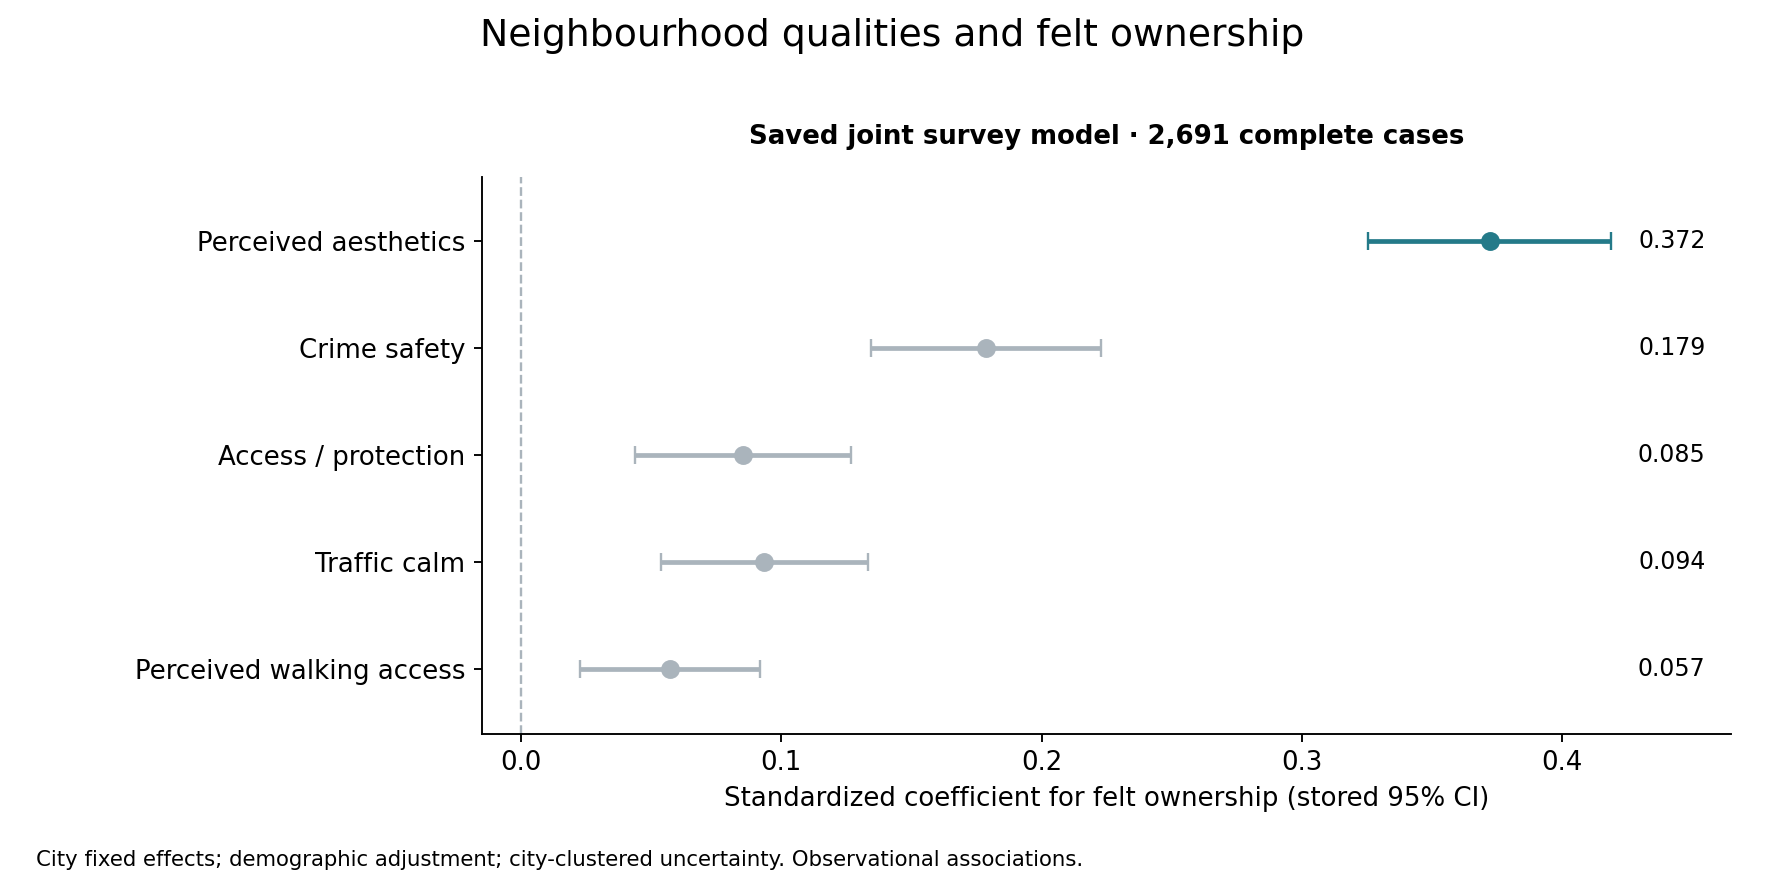

In [2]:
survey = pd.read_csv(ROOT / "results" / "selected_survey_coefficients.csv")
replay = pd.read_csv(ROOT / "results" / "selected_archived_replay_means.csv")
assert len(survey) == 5 and survey.respondent_n.eq(2691).all()
assert replay.outcome.tolist() == ["civic_action", "dosomething", "report", "steward"]
assert replay.incident_n.tolist() == [504, 504, 504, 246]
display(survey)
visuals.survey_associations(survey, FIGURES / "01_saved_survey_associations.png")
display(Image(filename=str(FIGURES / "01_saved_survey_associations.png")))

Five predictors appear in the same joint model, with demographic adjustment and city fixed effects.
The displayed confidence intervals were saved from city-clustered estimation; no model is refitted here.
This observational association does not estimate an intervention effect.

## Archived model judgments — selected repeated-visit incidents

,outcome,first_visit_mean_pct,history_mean_pct,incident_n
0,civic_action,22.868717,30.064484,504
1,dosomething,23.518519,31.772487,504
2,report,36.279762,38.571429,504
3,steward,25.934959,26.700542,246


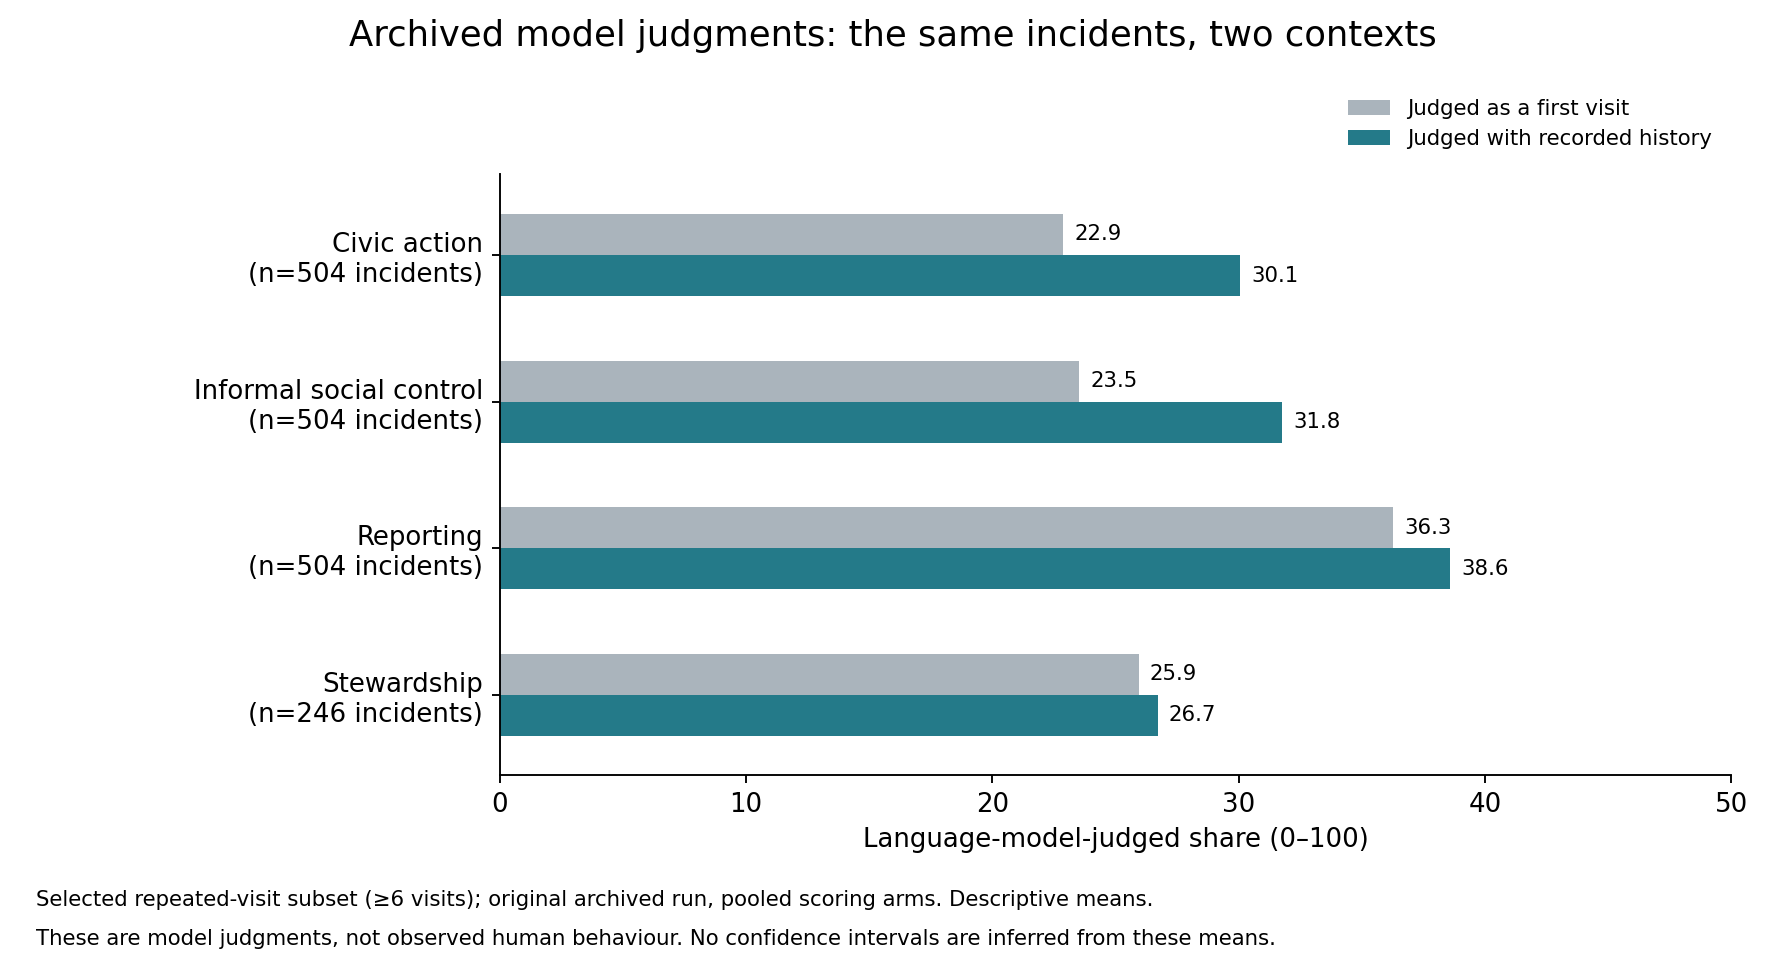

In [3]:
display(replay)
visuals.archived_replay(replay, FIGURES / "02_saved_archived_replay.png")
display(Image(filename=str(FIGURES / "02_saved_archived_replay.png")))

Pairs use the same six-or-more-visit incidents, judged with history versus as a first visit.
Means follow the original archived-run summary, pooling original and swapped-scoring arms.
The values are language-model-judged shares on a 0–100 scale, not observed human actions.
This selected panel does not include the full study's calibration/scoring sensitivities.
No new confidence intervals or causal effects are calculated.

## Representative original analysis components for inspection

In [4]:
area = load_module("area_model_excerpt")
survey_code = load_module("survey_model_excerpt")
archived = load_module("archived_replay_excerpt")
assert callable(area.state_model) and callable(survey_code.fit_felt_ownership)
assert callable(archived.cluster_ols) and callable(archived._pub)
summary = {"survey": survey.to_dict(orient="records"), "archived_means": replay.to_dict(orient="records")}
(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "selected_results_receipt.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Representative modules imported. No models, agents or language-model calls were run.")

Representative modules imported. No models, agents or language-model calls were run.
